# Projet Aegis
### Etude de stabilité financieres en bourse

Downloading and extracting files compagny_tickers and zip from www.sec.gov 

In [ ]:
import re
import zipfile
from pathlib import Path
import requests
from bs4 import BeautifulSoup
import pandas as pd

# SEC EDGAR requires a custom User-Agent header
HEADERS = {
    "User-Agent": "ScriptPythonData chabot.arthur35@gmail.com",
    "Accept-Encoding": "gzip, deflate",
}
DATA_DIR = Path("./data_sec")


def get_sec_urls():
    """Scrape SEC page for quarterly financial statement ZIP URLs (2010+)."""
    url = "https://www.sec.gov/dera/data/financial-statement-data-sets.html"
    response = requests.get(url, headers=HEADERS, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    urls = []

    for a in soup.find_all("a", href=True):
        href = a["href"]
        match = re.search(r"(20\d{2})q[1-4]\.zip$", href.lower())
        if match and int(match.group(1)) >= 2010:
            full_url = f"https://www.sec.gov{href}" if href.startswith("/") else href
            if full_url not in urls:
                urls.append(full_url)

    print(f"Found {len(urls)} SEC archives (2010+).")
    return urls


def download_and_convert(urls):
    """Download each quarterly ZIP and convert its TXT tables directly to Parquet."""
    for i, url in enumerate(urls, 1):
        zip_path = DATA_DIR / Path(url).name
        quarter_dir = DATA_DIR / zip_path.stem
        quarter_dir.mkdir(parents=True, exist_ok=True)

        print(f"[{i}/{len(urls)}] Processing {zip_path.name}...")
        try:
            with requests.get(url, headers=HEADERS, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(zip_path, "wb") as f:
                    for chunk in r.iter_content(chunk_size=65536):
                        f.write(chunk)

            with zipfile.ZipFile(zip_path, "r") as archive:
                for member in archive.namelist():
                    if member.lower().endswith(".txt"):
                        parquet_path = quarter_dir / Path(member).with_suffix(".parquet").name
                        if not parquet_path.exists():
                            with archive.open(member) as txt_file:
                                df = pd.read_csv(txt_file, sep="\t", low_memory=False, on_bad_lines="skip")
                                df.to_parquet(parquet_path, engine="pyarrow")
            zip_path.unlink()
        except Exception as err:
            print(f"Failed on {zip_path.name}: {err}")


if (DATA_DIR / "2010q1").is_dir():
    print("SEC dataset already exists. Skipping download.")
else:
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    # Download CIK-to-Ticker mapping
    resp = requests.get("https://www.sec.gov/files/company_tickers.json", headers=HEADERS, timeout=60)
    resp.raise_for_status()
    (DATA_DIR / "company_tickers.json").write_text(resp.text, encoding="utf-8")

    sec_urls = get_sec_urls()
    download_and_convert(sec_urls)
    print("Done.")

Found 67 SEC archives (2010+).
[1/67] Processing 2026q3.zip...
[2/67] Processing 2026q2.zip...


Utilisation de DuckDB pour le stockage de toutes ces informations

In [ ]:
import time
import duckdb

query = """
WITH filtered AS (
    SELECT 
        s.cik,
        s.name AS company_name,
        s.filed AS filing_date,
        s.adsh,
        n.tag,
        n.value
    FROM read_parquet('data_sec/*/sub.parquet') s
    JOIN read_parquet('data_sec/*/num.parquet') n ON s.adsh = n.adsh
    WHERE s.form = '10-K'
      AND (n.coreg IS NULL OR n.coreg = '') -- parent company only
      AND n.ddate = s.period                -- match reporting period, skip prior years
      AND n.tag IN (
          'Assets', 'Liabilities', 'Revenues', 'SalesRevenueNet',
          'OperatingIncomeLoss', 'NetIncomeLoss',
          'NetCashProvidedByUsedInOperatingActivities'
      )
)
SELECT 
    cik,
    company_name,
    filing_date,
    adsh,
    MAX(CASE WHEN tag = 'Assets' THEN value END) AS Assets,
    MAX(CASE WHEN tag = 'Liabilities' THEN value END) AS Liabilities,
    MAX(CASE WHEN tag IN ('Revenues', 'SalesRevenueNet') THEN value END) AS Revenues,
    MAX(CASE WHEN tag = 'OperatingIncomeLoss' THEN value END) AS OperatingIncome,
    MAX(CASE WHEN tag = 'NetIncomeLoss' THEN value END) AS NetIncome,
    MAX(CASE WHEN tag = 'NetCashProvidedByUsedInOperatingActivities' THEN value END) AS OperatingCash
FROM filtered
GROUP BY cik, company_name, filing_date, adsh
"""

t0 = time.time()
df = duckdb.sql(query).df().dropna()
df.to_parquet("dataset_aegis_fondamentaux.parquet")

print(f"Extracted {len(df)} records in {time.time() - t0:.1f}s")
print(df.head())

Exécution de la requête sur les fichiers Parquet (cela peut prendre 1 à 3 minutes)...
Extraction terminée en 22.54 secondes !

Succès ! Fichier 'dataset_aegis_fondamentaux.parquet' créé avec succès.
Total : 21166 bilans annuels complets extraits sur 20 ans.

Aperçu des 5 premières lignes :
       cik                  company_name  filing_date                  adsh  \
0  1307954                 HUNTSMAN CORP     20110217  0001047469-11-001007   
1    66740                         3M CO     20110216  0001104659-11-007845   
2  1001604             EMERITUS CORP\WA\     20110311  0001001604-11-000022   
3    72207              NOBLE ENERGY INC     20110210  0001140361-11-007888   
5  1174746  INTERCONTINENTALEXCHANGE INC     20110209  0001193125-11-028245   

         Assets   Liabilities      Revenues  OperatingIncome     NetIncome  \
0  8.714000e+09  6.864000e+09  9.250000e+09     4.100000e+08  2.700000e+07   
1  3.015600e+10  1.413900e+10  2.666200e+10     5.918000e+09  4.085000e+09   


Code qui se charge de la jointure cik et tickers car yfinance (info bourses) utilise le tickers.

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf


def compute_calmar(prices: pd.Series) -> dict:
    prices = prices.ffill().dropna()
    if len(prices) < 10 or prices.iloc[0] <= 0:
        return {"return": np.nan, "max_dd": np.nan, "calmar": np.nan}

    ret = (prices.iloc[-1] - prices.iloc[0]) / prices.iloc[0]
    peaks = prices.cummax()
    max_dd = ((prices - peaks) / peaks).min()

    # 1% floor to prevent division by zero on flat/monotonic series
    calmar = ret / max(abs(max_dd), 0.01)

    return {"return": ret, "max_dd": max_dd, "calmar": calmar}


if __name__ == "__main__":
    df = yf.download("AAPL", start="2023-01-01", end="2023-12-31", progress=False)
    close = df["Close"].squeeze()

    res = compute_calmar(close)
    print(
        f"AAPL 2023 | Return: {res['return']:.2%} | "
        f"Max DD: {res['max_dd']:.2%} | Calmar: {res['calmar']:.2f}"
    )

Téléchargement des données d'Apple (AAPL) pour l'année 2023...

--- RÉSULTATS APPLE 2023 ---
Rendement annuel : 54.80 %
Pire chute (Max Drawdown) : -14.93 %
SCORE DE STABILITÉ : 3.67


In [ ]:
import pandas as pd

df_sec = pd.read_parquet("dataset_aegis_fondamentaux_avec_tickers.parquet")
print(df_sec.columns.tolist())

['cik', 'company_name', 'filing_date', 'adsh', 'Assets', 'Liabilities', 'Revenues', 'OperatingIncome', 'NetIncome', 'OperatingCash', '__index_level_0__', 'Ticker']


In [ ]:
import time
import pandas as pd
import yfinance as yf

df_sec = pd.read_parquet("dataset_aegis_fondamentaux_avec_tickers.parquet")
df_sec["filing_date"] = pd.to_datetime(
    df_sec["filing_date"].astype(str), format="%Y%m%d", errors="coerce"
)

tickers = df_sec["Ticker"].dropna().astype(str).unique().tolist()
start_date = f"{df_sec['filing_date'].dt.year.min()}-01-01"
end_date = f"{df_sec['filing_date'].dt.year.max() + 2}-01-01"

print(f"Downloading {len(tickers)} tickers ({start_date} to {end_date})...")
raw_prices = yf.download(tickers, start=start_date, end=end_date)

t0 = time.time()
# Convert wide (Price, Ticker) MultiIndex to long format
df_prices = raw_prices.stack(level=1, future_stack=True).reset_index()
df_prices.columns = [str(c).replace(" ", "_").lower() for c in df_prices.columns]

# Keep only valid close prices for target computation
df_prices = df_prices[["date", "ticker", "close"]].dropna(subset=["close"])
df_prices.to_parquet("dataset_aegis_prix_historiques_clean.parquet", index=False)

print(f"Saved {len(df_prices)} rows in {time.time() - t0:.1f}s")
print(df_prices.head())

[                       0%                       ]  2 of 2406 completed

Téléchargement HUN, MMM, BCO, CHE, UDR, FN, STX, LFVN, CVSA, CALM, LUVU, UI, DLB, ESOA, CMTL, SMG, ARKR, BRFH, KBH, VPG, WFRD, NPKI, FSS, LOAN, CODI-PA, ACIC, ERNAW, PTCT, SCKT, NEON, MRKR, UUUU, INVX, UNH, CNC, JFILD, AIRTP, IQST, FC, BRBR, LCID, GIPR, CYH, CKX, MBRX, PACK, RLEA, HOLOW, QXO-PB, OSW, WLKP, CTSH, WKC, FPI, LGSP, SOBR, MTWO, DYNR, BGLC, AAPI, QSEP, FULO, AIM, AUC, EPC, MAS, AIT, TPR, AMAT, SPH, PRKA, V, BEN, NCPLW, LITE, ATEN, MWA, QSJC, IPW, WTER, LTRX, NRIS, YBGJ, BOTX, SYK, RIOT, ENBNF, VBIO, CLW, VNDA, TRS, GPRE, SMTK, BLNK, CPHI, BURUW, IEHC, SKVI, AMWL, RPRX, CCO, LODE, TKO, MDAIW, PLUG, AUUD, GXAI, UEC, MMEX, ASTH, KRMD, RTB, PCSV, CETY, RDCT, MNTR, QPRC, LBRA, TOON, KCRD, TKLS, KRFG, FEIM, AXIL, GTBP, VSAT, AAT, TER, DOGP, AIV, FWFW, ENOV, WYY, NOVTU, EXLS, IMAX, FOXF, CREX, EACO, AIFF, UHAL-B, WYTC, NTCT, ELTP, INLX, BPTH, DTST, OLB, RCAT, SNWV, KTEL, NNN, CRTD, ITP, NINE, PXLW, TRC, CBRE, MOH, TCI, VTOL, NVAX, NFEGP, PEN, DNTH, FUST, BKTI, ALDS, INMB, RLAY, SEI

[**                     4%                       ]  103 of 2406 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: GCGJ"}}}
[**                     5%                       ]  114 of 2406 completed$GCGJ: possibly delisted; no timezone found
[**                     5%                       ]  115 of 2406 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: VEST"}}}
[**                     5%                       ]  117 of 2406 completed$VEST: possibly delisted; no timezone found
[****                   8%                       ]  201 of 2406 completed$NCL: possibly delisted; no timezone found
[*****                 10%                       ]  238 of 2406 completed$TVCN: possibly delisted; no timezone found
[*****                 10%                       ]  251 of 2406 completed$ZARE: possibly delisted; no timezone found
[*****          

KeyboardInterrupt: 

$NONE.: possibly delisted; no timezone found
[****************      34%                       ]  830 of 2406 completed$DNKC: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[********************  41%                       ]  993 of 2406 completed$GGBY: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[********************  42%                       ]  1013 of 2406 completed$FGRS: possibly delisted; no timezone found
[********************* 43%                       ]  1032 of 2406 completed$ESMR: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[**********************48%                       ]  1145 of 2406 completed$LLPS: possibly delisted; no timezone found
[**********************63%*****                  ]  1511 of 2406 completed$TCRG: possibly delisted; no price data found  (1d 2010-01-01 -> 2028-01-01)
[**********************65%******                 ]  1565 of 2406 completed$CLBZ: possibly delisted; no timezone found

Clean pandas afin de reduire le nombre de lignes de ce fichiers de 10 148 508 lignes, en enlevant les Not a Numbre (NaN) pour les entreprises "mortes" et les jours sans bourses. Ensuite on ne garde que les colonnes souhaités pour le fichier de test soit 3 lignes : date, ticker, close.

In [ ]:
import pandas as pd

df = pd.read_parquet("dataset_aegis_prix_historiques.parquet")
n_raw = len(df)

df_clean = df[["date", "ticker", "close"]].dropna(subset=["close"])
df_clean.to_parquet("dataset_aegis_prix_historiques_clean.parquet", index=False)

print(f"Kept {len(df_clean)} rows (dropped {n_raw - len(df_clean)} empty rows)")
print(df_clean.head())

Lignes avant nettoyage : 10148508
Lignes après nettoyage : 7050636
Lignes supprimées : 3097872
         date ticker        close
33 2010-01-04   AAME     1.164885
36 2010-01-04   AAPI    16.000000
37 2010-01-04   AAPL     6.400959
41 2010-01-04   ABEO  4000.000000
42 2010-01-04   ABIT     0.100000


creation 

In [ ]:
import time
import numpy as np
import pandas as pd
from tqdm import tqdm

df_sec = pd.read_parquet("dataset_aegis_fondamentaux_avec_tickers.parquet")
df_prices = pd.read_parquet("dataset_aegis_prix_historiques_clean.parquet")

df_sec["filing_date"] = pd.to_datetime(
    df_sec["filing_date"].astype(str), format="%Y%m%d", errors="coerce"
)
df_prices["date"] = pd.to_datetime(df_prices["date"])
df_sec = df_sec.dropna(subset=["filing_date"])

# MultiIndex for fast slicing by ticker and date range
df_prices = df_prices.set_index(["ticker", "date"]).sort_index()
df_sec["y_score_calmar_1an"] = np.nan

t0 = time.time()
for idx, row in tqdm(df_sec.iterrows(), total=len(df_sec), desc="Computing Calmar"):
    ticker = row["Ticker"]
    start_dt = row["filing_date"]
    end_dt = start_dt + pd.Timedelta(days=365)

    try:
        prices_1y = df_prices.loc[ticker].loc[start_dt:end_dt, "close"]
        if len(prices_1y) >= 200:  # minimum ~1 trading year
            ret = (prices_1y.iloc[-1] - prices_1y.iloc[0]) / prices_1y.iloc[0]
            peaks = prices_1y.cummax()
            max_dd = ((prices_1y - peaks) / peaks).min()

            df_sec.at[idx, "y_score_calmar_1an"] = ret / max(abs(max_dd), 0.01)
    except KeyError:
        continue

valid_count = df_sec["y_score_calmar_1an"].notna().sum()
print(f"Matched {valid_count}/{len(df_sec)} filings in {time.time() - t0:.1f}s")

df_sec.to_parquet("dataset_aegis_final_ml.parquet")

cols = ["Ticker", "company_name", "filing_date", "y_score_calmar_1an"]
print(df_sec.dropna(subset=["y_score_calmar_1an"])[cols].head())

Chargement des données...
Indexation de la base de prix (le secret pour passer de 2h à 5 secondes)...

Début du calcul des scores pour 12596 bilans...


100%|██████████| 12596/12596 [00:05<00:00, 2255.93it/s]


Boucle terminée en 5.59 secondes !

--- RÉSULTATS ---
Bilans financiers associés à un score valide : 10281 / 12596

Sauvegarde du Dataset Final...
Terminé ! Voici un aperçu :
  Ticker                       company_name filing_date  y_score_calmar_1an
0   TRCK                  SECUREALERT, INC.  2011-12-29            0.000000
1   AMSC  AMERICAN SUPERCONDUCTOR CORP /DE/  2012-06-06           -0.704865
2   EGHT                       8X8 INC /DE/  2012-05-24            3.930694
3   TRNS                       TRANSCAT INC  2012-06-20           -0.424461
4    MTX          MINERALS TECHNOLOGIES INC  2013-02-22            1.580233


In [ ]:
import numpy as np
import pandas as pd

df = pd.read_parquet("dataset_aegis_final_ml.parquet")
scores = df["y_score_calmar_1an"].dropna()

print(f"Valid filings : {len(scores)}")
print(f"Median        : {scores.median():.2f}")
print(f"Mean          : {scores.mean():.2f}")
print(f"Min / Max     : {scores.min():.2f} / {scores.max():.2f}")
print(f"90th / 99th % : {np.percentile(scores, 90):.2f} / {np.percentile(scores, 99):.2f}")

--- ANALYSE DES OUTLIERS (SCORE DE STABILITÉ) ---
Nombre de bilans évalués : 10281
Score Médian (le milieu) : 0.09
Score Moyen (déformé par les outliers) : 7.90
Pire score : -59.02
Meilleur score absolu : 39999.59

--- DISTRIBUTION ---
90% des actions ont un score inférieur à : 3.43
99% des actions ont un score inférieur à : 13.49


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier

df = pd.read_parquet("dataset_aegis_final_ml.parquet").dropna(subset=["y_score_calmar_1an"])

# Sort chronologically before extracting X and y to prevent look-ahead bias
df = df.sort_values("filing_date").reset_index(drop=True)
df["is_compounder"] = (df["y_score_calmar_1an"] >= 1.0).astype(int)

features = ["Assets", "Liabilities", "Revenues", "OperatingIncome", "NetIncome", "OperatingCash"]
X = df[features].fillna(0)
y = df["is_compounder"]

split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

cutoff = df.loc[split_idx, "filing_date"].date()
print(f"Class balance (%):\n{(y.value_counts(normalize=True) * 100).round(1)}\n")
print(f"Split date: {cutoff} (Train: {len(X_train)}, Test: {len(X_test)})")

dt_model = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)
print(f"\nTest Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred, target_names=["Underperform (0)", "Compounder (1)"]))

1. Préparation des données...
Répartition des classes : 
is_compounder
0    70.0
1    30.0
Name: proportion, dtype: float64 %

2. Fractionnement Temporel (Train / Test Split)...
Entraînement sur les bilans avant : 2023-03-31
Test sur les bilans après : 2023-03-31

3. Entraînement de l'Arbre de Décision (V1)...

4. Évaluation sur les données de test (Le monde réel) :
Précision globale (Accuracy) : 54.45 %

Rapport détaillé :
                precision    recall  f1-score   support

   Mauvais (0)       0.75      0.53      0.62      1453
Compounder (1)       0.34      0.57      0.42       604

      accuracy                           0.54      2057
     macro avg       0.54      0.55      0.52      2057
  weighted avg       0.63      0.54      0.56      2057




5. Génération des graphiques pour le GitHub...
- Image 'github_arbre_decision.png' sauvegardée.
- Image 'github_feature_importance.png' sauvegardée.


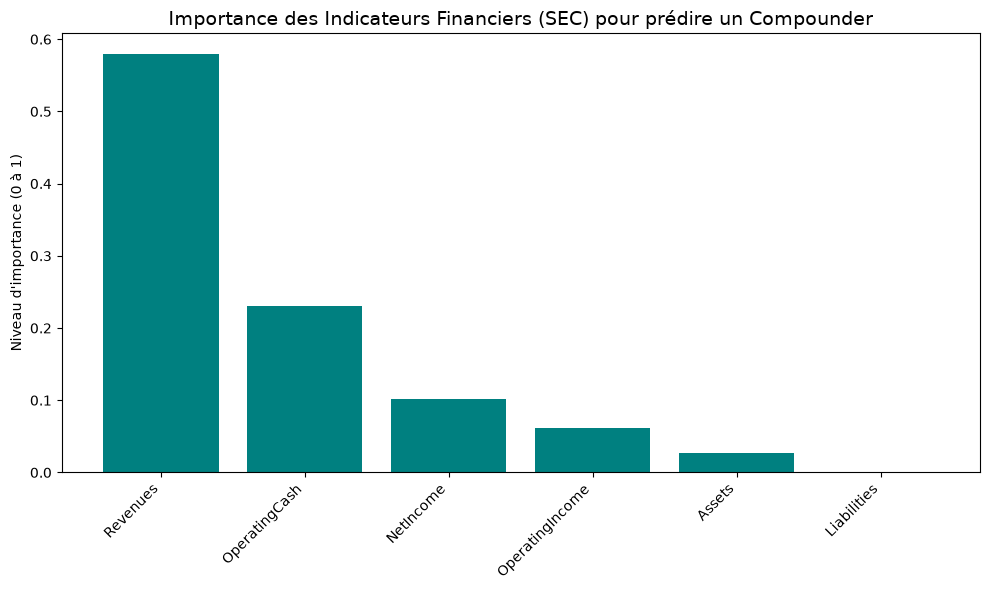

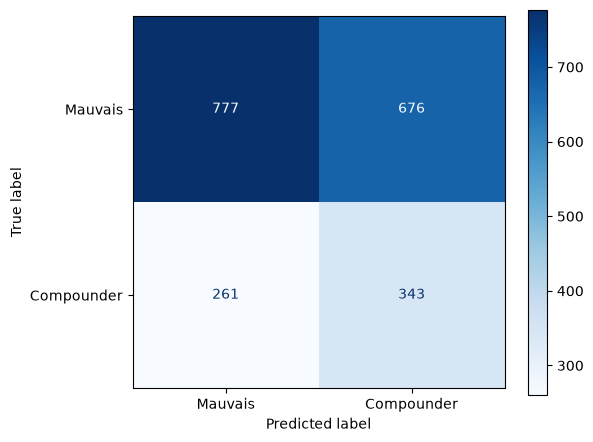

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=features,
    class_names=["Underperform", "Compounder"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10,
)
plt.title("Decision Tree Baseline (Top 3 Levels)", fontsize=14)
plt.savefig("github_arbre_decision.png", dpi=300, bbox_inches="tight")
plt.close()

importances = dt_model.feature_importances_
order = np.argsort(importances)[::-1]

plt.figure(figsize=(9, 5))
plt.bar(range(len(features)), importances[order], color="teal")
plt.xticks(range(len(features)), [features[i] for i in order], rotation=45, ha="right")
plt.title("Feature Importance - Decision Tree", fontsize=13)
plt.ylabel("Importance")
plt.tight_layout()
plt.savefig("github_feature_importance.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    dt_model, X_test, y_test, display_labels=["Underperform", "Compounder"], cmap="Blues", ax=ax
)
plt.title("Confusion Matrix - Decision Tree", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf_model.predict(X_train))
test_acc = accuracy_score(y_test, rf_model.predict(X_test))

print(f"Accuracy | Train: {train_acc:.2%} | Test: {test_acc:.2%}\n")
print(classification_report(y_test, rf_model.predict(X_test), target_names=["Underperform (0)", "Compounder (1)"]))

plt.figure(figsize=(22, 10))
plot_tree(
    rf_model.estimators_[0],
    feature_names=features,
    class_names=["Underperform", "Compounder"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
)
plt.title("Random Forest - Sample Tree (Estimator 0)", fontsize=14)
plt.savefig("github_foret_arbre_exemple.png", dpi=300, bbox_inches="tight")
plt.close()

rf_imp = rf_model.feature_importances_
rf_order = np.argsort(rf_imp)[::-1]

plt.figure(figsize=(9, 5))
plt.bar(range(len(features)), rf_imp[rf_order], color="forestgreen")
plt.xticks(range(len(features)), [features[i] for i in rf_order], rotation=45, ha="right")
plt.title("Feature Importance - Random Forest (100 Trees)", fontsize=13)
plt.ylabel("Relative Weight")
plt.tight_layout()
plt.savefig("github_foret_feature_importance.png", dpi=300)
plt.close()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    rf_model, X_test, y_test, display_labels=["Underperform", "Compounder"], cmap="Blues", ax=ax
)
plt.title("Confusion Matrix - Random Forest (Test Set)", fontsize=13)
plt.tight_layout()
plt.savefig("github_foret_matrice_confusion.png", dpi=300)
plt.close()

Entraînement de la Random Forest...

Accuracy Train : 60.57 %
Accuracy Test  : 54.30 %

Rapport détaillé sur le jeu de test :
                precision    recall  f1-score   support

   Mauvais (0)       0.77      0.51      0.61      1453
Compounder (1)       0.35      0.63      0.45       604

      accuracy                           0.54      2057
     macro avg       0.56      0.57      0.53      2057
  weighted avg       0.64      0.54      0.56      2057

Image 'github_foret_arbre_exemple.png' enregistrée.
Image 'github_foret_feature_importance.png' enregistrée.
Image 'github_foret_matrice_confusion.png' enregistrée.
